<a href="https://colab.research.google.com/github/EmanAdil122/federated-eeg-working-memory/blob/main/notebooks/EEG_Batch_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
participant_ids = ["sub-003", "sub-004", "sub-005", "sub-006"]

from pathlib import Path
from urllib.parse import quote
import xml.etree.ElementTree as ET

import pandas as pd
import requests
from IPython.display import display

project = Path("/content/federated-eeg-working-memory")
data_dir = project / "data"
bucket = "https://s3.amazonaws.com/openneuro.org"
dataset = "ds003655"
ns = {"s3": "http://s3.amazonaws.com/doc/2006-03-01/"}


def list_eeg_files(session, participant):
    params = {
        "list-type": "2",
        "prefix": f"{dataset}/{participant}/eeg/",
    }
    files = []

    while True:
        response = session.get(bucket, params=params, timeout=60)
        response.raise_for_status()
        root = ET.fromstring(response.content)

        for item in root.findall("s3:Contents", ns):
            key = item.findtext("s3:Key", namespaces=ns)
            size = int(item.findtext("s3:Size", namespaces=ns))
            if not key.endswith("/"):
                files.append((key, size))

        token = root.findtext("s3:NextContinuationToken", namespaces=ns)
        if not token:
            return files
        params["continuation-token"] = token


def download_file(session, key, size, target):
    if target.is_file() and target.stat().st_size == size:
        return

    partial = target.with_name(target.name + ".part")
    with session.get(
        f"{bucket}/{quote(key, safe='/')}",
        stream=True,
        timeout=(15, 120),
    ) as response:
        response.raise_for_status()
        with partial.open("wb") as output:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                output.write(chunk)

    if partial.stat().st_size != size:
        raise IOError(f"Size check failed for {target.name}. Run the cell again.")

    partial.replace(target)


summary = []

with requests.Session() as session:
    # Check all four participants before downloading any files.
    inventories = {}
    for participant in participant_ids:
        inventory = list_eeg_files(session, participant)
        required_suffixes = ("_eeg.set", "_eeg.fdt", "_events.tsv")
        missing = [
            suffix for suffix in required_suffixes
            if not any(key.endswith(suffix) and size > 0 for key, size in inventory)
        ]
        if missing:
            raise FileNotFoundError(f"{participant}: missing {', '.join(missing)}")
        inventories[participant] = inventory

    for participant, inventory in inventories.items():
        folder = data_dir / participant / "eeg"
        folder.mkdir(parents=True, exist_ok=True)
        print(f"Downloading or checking {participant}...", flush=True)

        for key, size in inventory:
            download_file(session, key, size, folder / Path(key).name)

        summary.append({
            "participant": participant,
            "files_verified": len(inventory),
            "size_MB": round(sum(size for _, size in inventory) / 1_000_000, 2),
            "status": "Ready",
        })

display(pd.DataFrame(summary))

,participant,files_verified,size_MB,status
0,sub-003,8,138.07,Ready
1,sub-004,8,135.96,Ready
2,sub-005,8,146.95,Ready
3,sub-006,8,139.22,Ready


In [3]:

from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

participant_ids = ["sub-003", "sub-004", "sub-005", "sub-006"]
data_dir = Path("/content/federated-eeg-working-memory/data")
output_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
output_dir.mkdir(parents=True, exist_ok=True)

conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
stage_prefixes = {
    "baseline": "start of the baseline period",
    "encoding": "encoding:",
    "delay": "delay period:",
    "probe": "probe:",
}
rows = []

for participant in participant_ids:
    eeg_dir = data_dir / participant / "eeg"
    event_files = sorted(eeg_dir.glob("*_events.tsv"))
    if len(event_files) != 1:
        raise ValueError(
            f"{participant}: expected one events file, found {len(event_files)}."
        )

    events = pd.read_csv(event_files[0], sep="\t")
    events["onset"] = pd.to_numeric(events["onset"], errors="coerce")
    events["label"] = events["trial_type"].fillna("").str.strip().str.lower()

    task_marker = events["label"].eq("start of the trial")
    for prefix in stage_prefixes.values():
        task_marker |= events["label"].str.startswith(prefix)

    if not np.isfinite(events.loc[task_marker, "onset"]).all():
        raise ValueError(f"{participant}: task marker has an invalid onset.")

    events = events.sort_values("onset", kind="stable").reset_index(drop=True)
    starts = events.index[events["label"].eq("start of the trial")].tolist()

    for trial_number, (start, stop) in enumerate(
        zip(starts, starts[1:] + [len(events)]), start=1
    ):
        trial_events = events.iloc[start:stop]
        row = {
            "participant_id": participant,
            "trial_number": trial_number,
            "trial_start_onset": events.at[start, "onset"],
        }
        issues = []
        stage_conditions = []

        for stage, prefix in stage_prefixes.items():
            markers = trial_events.loc[trial_events["label"].str.startswith(prefix)]
            row[f"{stage}_onset"] = np.nan
            if len(markers) != 1:
                issues.append(f"{stage}_markers={len(markers)}")
                continue

            row[f"{stage}_onset"] = markers["onset"].iloc[0]
            label = markers["label"].str.upper().str.extract(
                r"\b([567][RM])\b", expand=False
            ).iloc[0]
            if pd.isna(label):
                issues.append(f"{stage}_condition_missing")
            else:
                stage_conditions.append(label)

        distinct_conditions = set(stage_conditions)
        row["condition"] = stage_conditions[0] if len(distinct_conditions) == 1 else None
        if len(distinct_conditions) > 1:
            issues.append("condition_mismatch")

        onsets = [row[f"{stage}_onset"] for stage in stage_prefixes]
        if np.isfinite(onsets).all():
            baseline, encoding, delay, probe = onsets
            if not row["trial_start_onset"] <= baseline < encoding < delay < probe:
                issues.append("stage_order")
            row["delay_duration_seconds"] = probe - delay
        else:
            row["delay_duration_seconds"] = np.nan

        row["event_status"] = "REVIEW" if issues else "PASS"
        row["event_issues"] = "; ".join(issues)
        rows.append(row)

if not rows:
    raise ValueError("No trial starts found in the four event files.")

trials = pd.DataFrame(rows)
summary = pd.crosstab(trials["participant_id"], trials["condition"]).reindex(
    index=participant_ids, columns=conditions, fill_value=0
)
summary["total_trials"] = (
    trials.groupby("participant_id").size().reindex(participant_ids, fill_value=0)
)
summary["event_review"] = (
    trials["event_status"].eq("REVIEW").groupby(trials["participant_id"])
    .sum().reindex(participant_ids, fill_value=0)
)

trials.to_csv(output_dir / "batch_trial_table.csv", index=False)
summary.to_csv(output_dir / "batch_event_summary.csv")

display(summary)
review = trials.loc[trials["event_status"].eq("REVIEW")]
if not review.empty:
    display(review[["participant_id", "trial_number", "condition", "event_issues"]])

print("Total trial rows:", len(trials))
print("Saved to Drive:", output_dir)

Mounted at /content/drive


condition,5R,6R,7R,5M,6M,7M,total_trials,event_review
participant_id,,,,,,,,
sub-003,20,20,20,20,20,20,120,0
sub-004,20,20,20,20,20,20,120,0
sub-005,20,20,20,20,20,20,120,0
sub-006,20,20,20,20,20,20,120,0


Total trial rows: 480
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006


In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

participant_ids = ["sub-003", "sub-004", "sub-005", "sub-006"]
data_dir = Path("/content/federated-eeg-working-memory/data")
output_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
output_dir.mkdir(parents=True, exist_ok=True)

conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
stage_prefixes = {
    "baseline": "start of the baseline period",
    "encoding": "encoding:",
    "delay": "delay period:",
    "probe": "probe:",
}
rows = []

for participant in participant_ids:
    eeg_dir = data_dir / participant / "eeg"
    event_files = sorted(eeg_dir.glob("*_events.tsv"))
    if len(event_files) != 1:
        raise ValueError(
            f"{participant}: expected one events file, found {len(event_files)}."
        )

    events = pd.read_csv(event_files[0], sep="\t")
    events["onset"] = pd.to_numeric(events["onset"], errors="coerce")
    events["label"] = events["trial_type"].fillna("").str.strip().str.lower()

    task_marker = events["label"].eq("start of the trial")
    for prefix in stage_prefixes.values():
        task_marker |= events["label"].str.startswith(prefix)

    if not np.isfinite(events.loc[task_marker, "onset"]).all():
        raise ValueError(f"{participant}: task marker has an invalid onset.")

    events = events.sort_values("onset", kind="stable").reset_index(drop=True)
    starts = events.index[events["label"].eq("start of the trial")].tolist()

    for trial_number, (start, stop) in enumerate(
        zip(starts, starts[1:] + [len(events)]), start=1
    ):
        trial_events = events.iloc[start:stop]
        row = {
            "participant_id": participant,
            "trial_number": trial_number,
            "trial_start_onset": events.at[start, "onset"],
        }
        issues = []
        stage_conditions = []

        for stage, prefix in stage_prefixes.items():
            markers = trial_events.loc[trial_events["label"].str.startswith(prefix)]
            row[f"{stage}_onset"] = np.nan
            if len(markers) != 1:
                issues.append(f"{stage}_markers={len(markers)}")
                continue

            row[f"{stage}_onset"] = markers["onset"].iloc[0]
            label = markers["label"].str.upper().str.extract(
                r"\b([567][RM])\b", expand=False
            ).iloc[0]
            if pd.isna(label):
                issues.append(f"{stage}_condition_missing")
            else:
                stage_conditions.append(label)

        distinct_conditions = set(stage_conditions)
        row["condition"] = stage_conditions[0] if len(distinct_conditions) == 1 else None
        if len(distinct_conditions) > 1:
            issues.append("condition_mismatch")

        onsets = [row[f"{stage}_onset"] for stage in stage_prefixes]
        if np.isfinite(onsets).all():
            baseline, encoding, delay, probe = onsets
            if not row["trial_start_onset"] <= baseline < encoding < delay < probe:
                issues.append("stage_order")
            row["delay_duration_seconds"] = probe - delay
        else:
            row["delay_duration_seconds"] = np.nan

        row["event_status"] = "REVIEW" if issues else "PASS"
        row["event_issues"] = "; ".join(issues)
        rows.append(row)

if not rows:
    raise ValueError("No trial starts found in the four event files.")

trials = pd.DataFrame(rows)
summary = pd.crosstab(trials["participant_id"], trials["condition"]).reindex(
    index=participant_ids, columns=conditions, fill_value=0
)
summary["total_trials"] = (
    trials.groupby("participant_id").size().reindex(participant_ids, fill_value=0)
)
summary["event_review"] = (
    trials["event_status"].eq("REVIEW").groupby(trials["participant_id"])
    .sum().reindex(participant_ids, fill_value=0)
)

trials.to_csv(output_dir / "batch_trial_table.csv", index=False)
summary.to_csv(output_dir / "batch_event_summary.csv")

display(summary)
review = trials.loc[trials["event_status"].eq("REVIEW")]
if not review.empty:
    display(review[["participant_id", "trial_number", "condition", "event_issues"]])

print("Total trial rows:", len(trials))
print("Saved to Drive:", output_dir)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


condition,5R,6R,7R,5M,6M,7M,total_trials,event_review
participant_id,,,,,,,,
sub-003,20,20,20,20,20,20,120,0
sub-004,20,20,20,20,20,20,120,0
sub-005,20,20,20,20,20,20,120,0
sub-006,20,20,20,20,20,20,120,0


Total trial rows: 480
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006


In [5]:
from pathlib import Path
import importlib.util
import json
import subprocess
import sys
import warnings

if importlib.util.find_spec("mne") is None:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "mne==1.13.2"],
        check=True,
    )

import mne
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning

participant_ids = ["sub-003", "sub-004", "sub-005", "sub-006"]
data_dir = Path("/content/federated-eeg-working-memory/data")
batch_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
trials = pd.read_csv(batch_dir / "batch_trial_table.csv")


def fit_participant_ica(participant):
    folder = batch_dir / participant
    folder.mkdir(exist_ok=True)

    raw_path = folder / f"{participant}_filtered_raw.fif"
    ica_path = folder / f"{participant}-ica.fif"
    scores_path = folder / "component_scores.csv"
    settings_path = folder / "ica_fit_settings.json"

    if all(path.is_file() for path in (raw_path, ica_path, scores_path, settings_path)):
        print(f"{participant}: using saved checkpoint.", flush=True)
        return pd.read_csv(scores_path), "Saved fit reused"

    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    if len(subject_trials) != 120 or not subject_trials["event_status"].eq("PASS").all():
        raise ValueError("Trial table needs review before ICA.")

    eeg_files = sorted((data_dir / participant / "eeg").glob("*_eeg.set"))
    if len(eeg_files) != 1:
        raise FileNotFoundError("Expected one EEG .set file. Check the download cell.")

    raw = mne.io.read_raw_eeglab(eeg_files[0], preload=False, verbose="ERROR")
    raw.set_channel_types({"EOGv": "eog", "EOGh": "eog"})
    if raw.info["sfreq"] != 500 or raw.get_channel_types().count("eeg") != 19:
        raise ValueError("Expected 500 Hz and 19 EEG channels.")

    first_delay = float(subject_trials["delay_onset"].min())
    last_probe = float(subject_trials["probe_onset"].max())
    if not 0 <= first_delay < last_probe <= raw.times[-1]:
        raise ValueError("Task onsets are outside the recording.")

    raw.crop(
        tmin=max(0, first_delay - 10),
        tmax=min(raw.times[-1], last_probe + 10),
    ).load_data()

    picks = mne.pick_types(raw.info, eeg=True, eog=True, exclude=[])
    if not np.isfinite(raw.get_data(picks=picks)).all():
        raise ValueError("Non-finite EEG or EOG samples in the task crop.")
    if (np.abs(raw.get_data(picks="eeg")) >= 10239e-6).any():
        raise ValueError("Boundary-level EEG samples in the task crop. Inspect before ICA.")

    print(f"{participant}: filtering and fitting ICA...", flush=True)
    raw.notch_filter([50], picks=picks, method="iir", verbose="ERROR")
    raw.filter(
        1, 40, picks=picks, method="iir",
        iir_params={"order": 4, "ftype": "butter"},
        verbose="ERROR",
    )
    raw.resample(100, verbose="ERROR")

    ica = mne.preprocessing.ICA(
        n_components=0.99, method="fastica", random_state=42, max_iter=1000
    )
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        ica.fit(raw, picks="eeg", verbose="ERROR")

    if ica.n_iter_ >= 1000 or any(
        issubclass(w.category, ConvergenceWarning) for w in caught
    ):
        raise RuntimeError("ICA did not converge. Review this participant.")

    scores = ica.score_sources(
        raw, target="EOGv", score_func="pearsonr", verbose="ERROR"
    )
    ranking = pd.DataFrame({
        "component": np.arange(ica.n_components_),
        "EOGv_correlation": scores,
        "absolute_correlation": np.abs(scores),
    }).sort_values("absolute_correlation", ascending=False)

    # Write settings last so an interrupted save can be retried.
    settings_path.unlink(missing_ok=True)
    raw.save(raw_path, overwrite=True, verbose="ERROR")
    ica.save(ica_path, overwrite=True, verbose="ERROR")
    ranking.to_csv(scores_path, index=False)
    settings_path.write_text(json.dumps({
        "participant": participant,
        "status": "ICA fitted; component review pending",
        "notch_Hz": 50,
        "bandpass_Hz": [1, 40],
        "bandpass_filter": "fourth-order Butterworth IIR",
        "sampling_rate_Hz": 100,
        "ica_method": "fastica",
        "ica_variance_setting": 0.99,
        "random_state": 42,
        "ica_iterations": int(ica.n_iter_),
        "excluded_components": [],
        "mne_version": mne.__version__,
    }, indent=2), encoding="utf-8")
    return ranking, "Fitted"


summary = []
for participant in participant_ids:
    try:
        ranking, status = fit_participant_ica(participant)
        top = ranking.iloc[0]
        summary.append({
            "participant": participant,
            "status": status,
            "components": len(ranking),
            "top_EOGv_component": int(top["component"]),
            "top_abs_EOGv_r": round(float(top["absolute_correlation"]), 3),
        })
    except (OSError, ValueError, RuntimeError) as error:
        summary.append({
            "participant": participant,
            "status": "REVIEW",
            "details": str(error),
        })

display(pd.DataFrame(summary))

Reading 0 ... 1222965  =      0.000 ...  2445.930 secs...
sub-003: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1224655  =      0.000 ...  2449.310 secs...
sub-004: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1223595  =      0.000 ...  2447.190 secs...
sub-005: filtering and fitting ICA...
Use rng= instead of random_state= in new code
Reading 0 ... 1223570  =      0.000 ...  2447.140 secs...
sub-006: filtering and fitting ICA...
Use rng= instead of random_state= in new code


,participant,status,components,top_EOGv_component,top_abs_EOGv_r
0,sub-003,Fitted,11,0,0.668
1,sub-004,Fitted,13,0,0.706
2,sub-005,Fitted,15,0,0.599
3,sub-006,Fitted,11,0,0.881



sub-003 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,0.668,0.668
1,3,0.351,0.351


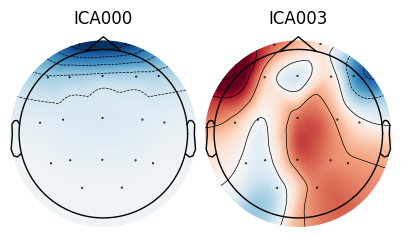

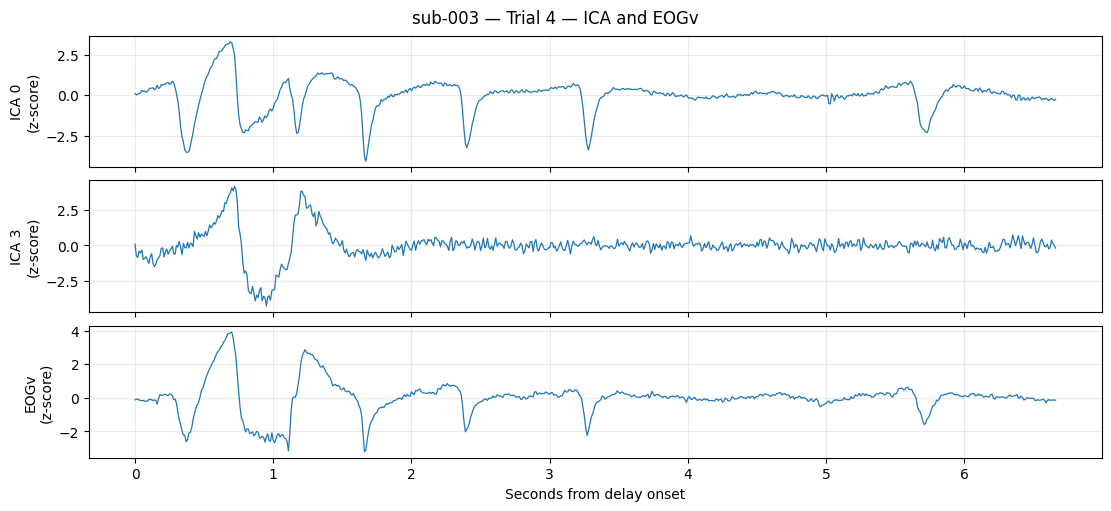


sub-004 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.706,0.706
1,1,0.195,0.195


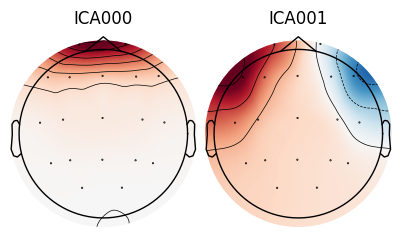

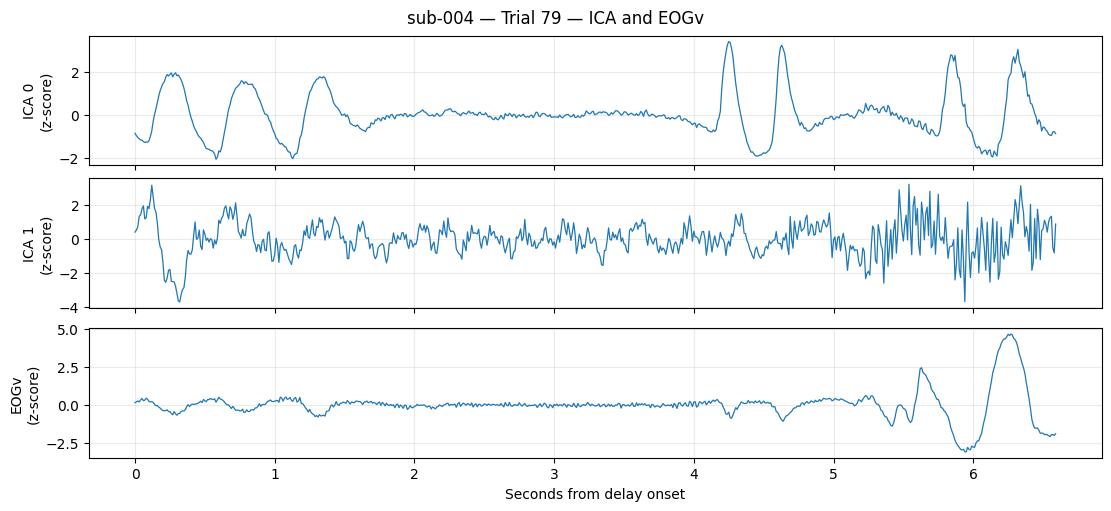


sub-005 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,-0.599,0.599
1,4,0.214,0.214


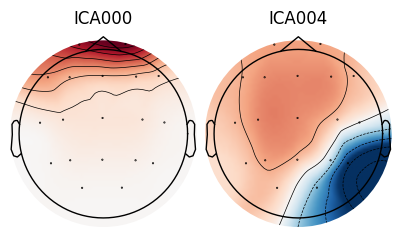

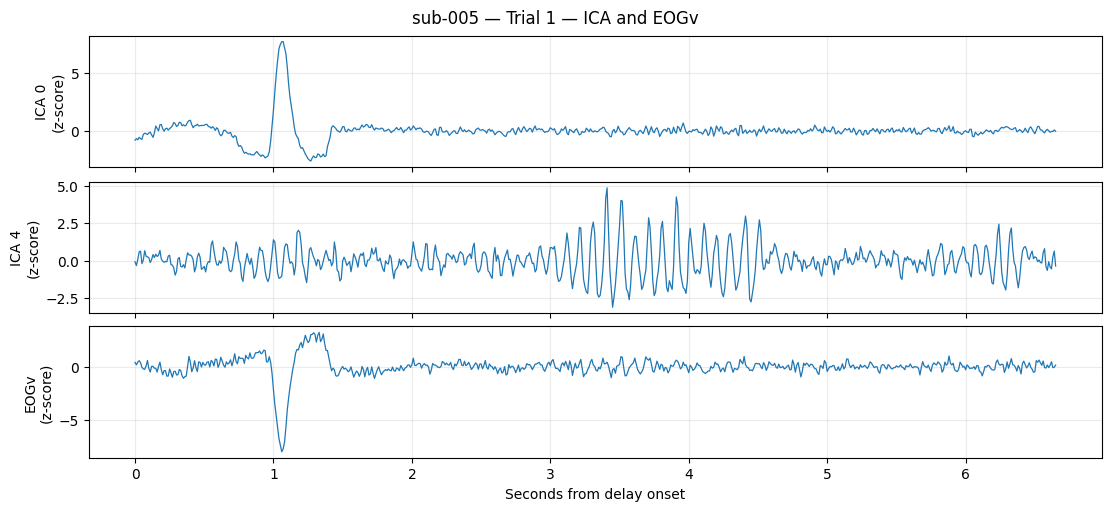


sub-006 — ICA candidates


,component,EOGv_correlation,absolute_correlation
0,0,0.881,0.881
1,2,0.181,0.181


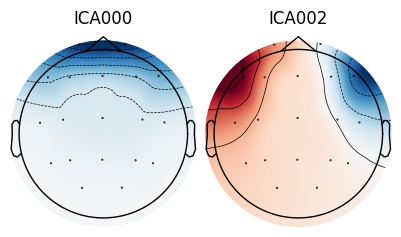

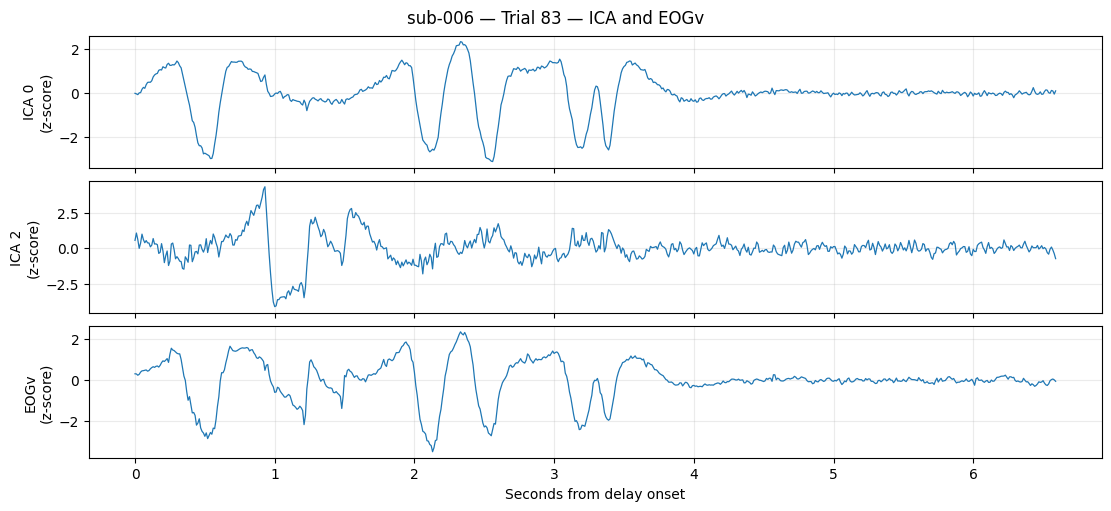

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

batch_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
participant_ids = ["sub-003", "sub-004", "sub-005", "sub-006"]
trials = pd.read_csv(batch_dir / "batch_trial_table.csv")
montage = mne.channels.make_standard_montage("colin27_1020")


def standardize(signal):
    sd = signal.std()
    return (signal - signal.mean()) / sd if sd > 0 else np.zeros_like(signal)


for participant in participant_ids:
    folder = batch_dir / participant
    raw = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif",
        preload=False,
        verbose="ERROR",
    )
    ica = mne.preprocessing.read_ica(
        folder / f"{participant}-ica.fif", verbose="ERROR"
    )
    ranking = pd.read_csv(folder / "component_scores.csv")
    candidates = ranking.nlargest(2, "absolute_correlation")
    picks = candidates["component"].astype(int).tolist()

    # Plot with standard electrode positions on a copy of the ICA fit.
    print(f"\n{participant} — ICA candidates")
    display(candidates.round(3))
    ica_plot = ica.copy()
    ica_plot.info.set_montage(montage, match_case=False, on_missing="raise")
    ica_plot.plot_components(picks=picks, show=True)

    fs = raw.info["sfreq"]
    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    strongest = None

    for trial in subject_trials.itertuples(index=False):
        start = round((trial.delay_onset - raw.first_time) * fs)
        stop = round((trial.probe_onset - raw.first_time) * fs)
        if not 0 <= start < stop <= raw.n_times:
            raise ValueError(f"{participant}: trial {trial.trial_number} outside recording.")

        eog = raw.get_data(picks=["EOGv"], start=start, stop=stop)[0]
        eog_range = np.ptp(eog)
        if strongest is None or eog_range > strongest["eog_range"]:
            strongest = {
                "trial": trial.trial_number,
                "start": start,
                "stop": stop,
                "eog": eog,
                "eog_range": eog_range,
            }

    sources = ica.get_sources(
        raw, start=strongest["start"], stop=strongest["stop"]
    ).get_data()
    eog = strongest["eog"]
    time = np.arange(len(eog)) / fs

    traces = [(f"ICA {index}", sources[index]) for index in picks]
    traces.append(("EOGv", eog))

    fig, axes = plt.subplots(
        len(traces), 1, figsize=(11, 5), sharex=True, constrained_layout=True
    )
    for ax, (label, signal) in zip(axes, traces):
        ax.plot(time, standardize(signal), linewidth=0.9)
        ax.set_ylabel(f"{label}\n(z-score)")
        ax.grid(alpha=0.25)

    axes[-1].set_xlabel("Seconds from delay onset")
    fig.suptitle(f"{participant} — Trial {strongest['trial']} — ICA and EOGv")
    plt.show()
    plt.close(fig)
    raw.close()

,recording_part,trial_number,eog_ptp_uV,ica0_EOGv_r
12,Early,13,224.675,0.152
78,Middle,79,827.343,-0.060
101,Late,102,301.365,-0.773


Median signed r across 120 trials: -0.826


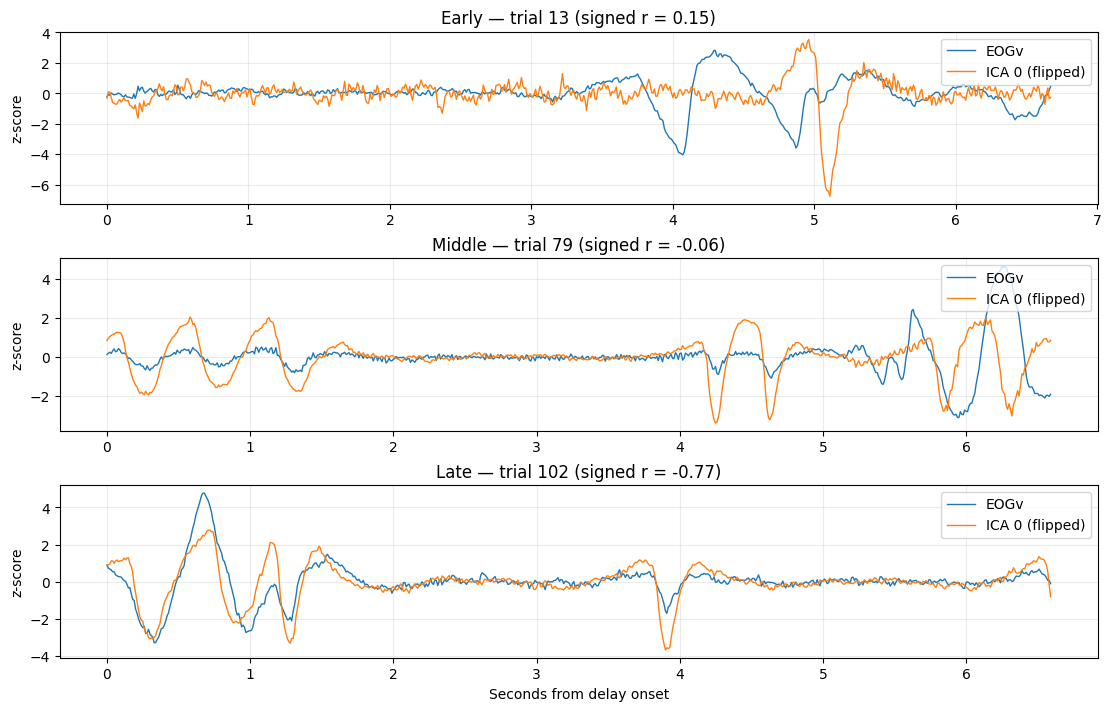

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import mne
import numpy as np
import pandas as pd
from IPython.display import display

batch_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
participant = "sub-004"
folder = batch_dir / participant

trials = pd.read_csv(batch_dir / "batch_trial_table.csv")
subject_trials = (
    trials.loc[trials["participant_id"].eq(participant)]
    .sort_values("trial_number")
    .reset_index(drop=True)
)
assert len(subject_trials) == 120

raw = mne.io.read_raw_fif(
    folder / f"{participant}_filtered_raw.fif",
    preload=False,
    verbose="ERROR",
)
ica = mne.preprocessing.read_ica(
    folder / f"{participant}-ica.fif", verbose="ERROR"
)

fs = raw.info["sfreq"]
eog = raw.get_data(picks=["EOGv"])[0]
component = ica.get_sources(raw).get_data(picks=[0])[0]
assert len(component) == len(eog) == raw.n_times


def zscore(signal):
    sd = signal.std()
    return (signal - signal.mean()) / sd if sd > 0 else np.zeros_like(signal)


rows = []
for position, trial in enumerate(subject_trials.itertuples(index=False)):
    start = round((trial.delay_onset - raw.first_time) * fs)
    stop = round((trial.probe_onset - raw.first_time) * fs)
    if not 0 <= start < stop <= raw.n_times:
        raise ValueError(f"Trial {trial.trial_number} is outside the recording.")

    eye = eog[start:stop]
    ic = component[start:stop]
    r = (
        np.corrcoef(ic, eye)[0, 1]
        if ic.std() > 0 and eye.std() > 0 else np.nan
    )
    rows.append({
        "trial_number": trial.trial_number,
        "recording_part": ["Early", "Middle", "Late"][position // 40],
        "eog_ptp_uV": np.ptp(eye) * 1e6,
        "ica0_EOGv_r": r,
        "start_sample": start,
        "stop_sample": stop,
    })

audit = pd.DataFrame(rows)
audit.to_csv(folder / "ica0_eogv_delay_review.csv", index=False)

selected = audit.loc[
    audit.groupby("recording_part")["eog_ptp_uV"].idxmax()
].sort_values("trial_number")

display(selected[
    ["recording_part", "trial_number", "eog_ptp_uV", "ica0_EOGv_r"]
].round(3))
print("Median signed r across 120 trials:", round(audit["ica0_EOGv_r"].median(), 3))

fig, axes = plt.subplots(3, 1, figsize=(11, 7), constrained_layout=True)
for ax, trial in zip(axes, selected.itertuples(index=False)):
    start, stop = trial.start_sample, trial.stop_sample
    time = np.arange(stop - start) / fs
    ax.plot(time, zscore(eog[start:stop]), label="EOGv", linewidth=1)
    ax.plot(time, -zscore(component[start:stop]), label="ICA 0 (flipped)", linewidth=1)
    ax.set_title(
        f"{trial.recording_part} — trial {trial.trial_number} "
        f"(signed r = {trial.ica0_EOGv_r:.2f})"
    )
    ax.set_ylabel("z-score")
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Seconds from delay onset")
plt.show()
plt.close(fig)
raw.close()

In [8]:
from pathlib import Path
import json

import mne
import numpy as np
import pandas as pd
from IPython.display import display

batch_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006"
)
trials = pd.read_csv(batch_dir / "batch_trial_table.csv")

# Decisions from each participant's scalp map and EOGv timing review.
decisions = {
    "sub-003": {"exclude": [0], "retain_reviewed": [3], "review_trials": [4]},
    "sub-004": {"exclude": [0], "retain_reviewed": [1], "review_trials": [13, 79, 102]},
    "sub-005": {"exclude": [0], "retain_reviewed": [4], "review_trials": [1]},
    "sub-006": {"exclude": [0], "retain_reviewed": [2], "review_trials": [83]},
}


def abs_corr(x, y):
    if x.std() == 0 or y.std() == 0:
        return np.nan
    return abs(np.corrcoef(x, y)[0, 1])


audit_rows = []

for participant, decision in decisions.items():
    print(f"{participant}: applying reviewed ICA and checking trials...", flush=True)
    folder = batch_dir / participant
    before = mne.io.read_raw_fif(
        folder / f"{participant}_filtered_raw.fif",
        preload=True,
        verbose="ERROR",
    )
    ica = mne.preprocessing.read_ica(
        folder / f"{participant}-ica.fif", verbose="ERROR"
    )
    ica.exclude = decision["exclude"]
    after = ica.apply(before.copy(), verbose="ERROR")

    eeg_names = [
        name for name, kind in zip(after.ch_names, after.get_channel_types())
        if kind == "eeg"
    ]
    assert len(eeg_names) == 19
    fp1, fp2 = [eeg_names.index(name) for name in ("Fp1", "Fp2")]

    fs = before.info["sfreq"]
    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    assert len(subject_trials) == 120
    assert subject_trials["event_status"].eq("PASS").all()

    participant_rows = []
    for trial in subject_trials.itertuples(index=False):
        start = round((trial.delay_onset - before.first_time) * fs)
        stop = round((trial.probe_onset - before.first_time) * fs)
        if not 0 <= start < stop <= before.n_times:
            raise ValueError(f"{participant}: trial {trial.trial_number} is out of bounds.")

        pre = before.get_data(picks=eeg_names, start=start, stop=stop)
        post = after.get_data(picks=eeg_names, start=start, stop=stop)
        eog = before.get_data(picks=["EOGv"], start=start, stop=stop)[0]
        if not np.isfinite(post).all():
            raise ValueError(f"{participant}: non-finite EEG in trial {trial.trial_number}.")

        post_ptp = np.ptp(post, axis=1) * 1e6
        participant_rows.append({
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "max_ptp_before_uV": np.ptp(pre, axis=1).max() * 1e6,
            "max_ptp_after_uV": post_ptp.max(),
            "largest_channel_after": eeg_names[int(post_ptp.argmax())],
            "Fp1_abs_r_before": abs_corr(pre[fp1], eog),
            "Fp1_abs_r_after": abs_corr(post[fp1], eog),
            "Fp2_abs_r_before": abs_corr(pre[fp2], eog),
            "Fp2_abs_r_after": abs_corr(post[fp2], eog),
            "flat_channels_after": int((post_ptp < 0.1).sum()),
            "over_500uV_after": bool(post_ptp.max() > 500),
            "visual_review_trial": trial.trial_number in decision["review_trials"],
        })

    after.save(folder / f"{participant}_cleaned_raw.fif", overwrite=True, verbose="ERROR")
    ica.save(folder / f"{participant}_reviewed-ica.fif", overwrite=True, verbose="ERROR")
    (folder / "ica_review_decision.json").write_text(
        json.dumps(decision, indent=2), encoding="utf-8"
    )
    audit_rows.extend(participant_rows)
    before.close()
    after.close()
    del before, after, ica

audit = pd.DataFrame(audit_rows)
assert len(audit) == 480
assert not audit.duplicated(["participant_id", "trial_number"]).any()

summary = audit.groupby("participant_id").agg(
    trials=("trial_number", "size"),
    median_max_ptp_before_uV=("max_ptp_before_uV", "median"),
    median_max_ptp_after_uV=("max_ptp_after_uV", "median"),
    highest_ptp_after_uV=("max_ptp_after_uV", "max"),
    median_Fp1_abs_r_before=("Fp1_abs_r_before", "median"),
    median_Fp1_abs_r_after=("Fp1_abs_r_after", "median"),
    median_Fp2_abs_r_before=("Fp2_abs_r_before", "median"),
    median_Fp2_abs_r_after=("Fp2_abs_r_after", "median"),
    trials_over_500uV=("over_500uV_after", "sum"),
    flat_channel_windows=("flat_channels_after", "sum"),
)

audit.to_csv(batch_dir / "batch_ica_quality_audit.csv", index=False)
summary.to_csv(batch_dir / "batch_ica_quality_summary.csv")

display(summary.round(3))
print("Sub-004 review trials after applying the decision:")
display(audit.loc[
    audit["participant_id"].eq("sub-004") & audit["visual_review_trial"],
    [
        "trial_number", "max_ptp_before_uV", "max_ptp_after_uV",
        "Fp1_abs_r_before", "Fp1_abs_r_after",
        "Fp2_abs_r_before", "Fp2_abs_r_after",
    ],
].round(3))
print("Saved to Drive:", batch_dir)

sub-003: applying reviewed ICA and checking trials...
sub-004: applying reviewed ICA and checking trials...
sub-005: applying reviewed ICA and checking trials...
sub-006: applying reviewed ICA and checking trials...


,trials,median_max_ptp_before_uV,median_max_ptp_after_uV,highest_ptp_after_uV,median_Fp1_abs_r_before,median_Fp1_abs_r_after,median_Fp2_abs_r_before,median_Fp2_abs_r_after,trials_over_500uV,flat_channel_windows
participant_id,,,,,,,,,,
sub-003,120,183.954,51.350,128.511,0.743,0.137,0.744,0.137,0,0
sub-004,120,247.527,90.845,205.737,0.783,0.218,0.799,0.157,0,0
sub-005,120,217.313,112.998,156.639,0.487,0.376,0.535,0.189,0,0
sub-006,120,253.664,72.518,211.896,0.834,0.233,0.863,0.136,0,0


Sub-004 review trials after applying the decision:


,trial_number,max_ptp_before_uV,max_ptp_after_uV,Fp1_abs_r_before,Fp1_abs_r_after,Fp2_abs_r_before,Fp2_abs_r_after
132,13,157.527,81.456,0.147,0.016,0.148,0.007
198,79,349.443,119.969,0.050,0.088,0.055,0.043
221,102,254.720,66.149,0.783,0.261,0.772,0.103


Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006


In [9]:
from pathlib import Path

import mne
import numpy as np
import pandas as pd
from scipy.signal import welch
from IPython.display import display

checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
batch_dir = checkpoints / "batch_sub003_to_sub006"
pilot_csv = (
    checkpoints / "sub-001_ICA_restored_20261107_184916_UTC"
    / "eeg_features_cleaned_signal.csv"
)

participants = ["sub-003", "sub-004", "sub-005", "sub-006"]
keys = ["participant_id", "trial_number"]
bands = {"theta": (4, 8), "alpha": (8, 13), "beta": (13, 30)}

trials = pd.read_csv(batch_dir / "batch_trial_table.csv")
quality = pd.read_csv(batch_dir / "batch_ica_quality_audit.csv")
pilot_columns = pd.read_csv(pilot_csv, nrows=0).columns
feature_columns = [name for name in pilot_columns if name.endswith("_power")]
assert len(feature_columns) == 57

rows = []

for participant in participants:
    print(f"Extracting features: {participant}", flush=True)
    raw = mne.io.read_raw_fif(
        batch_dir / participant / f"{participant}_cleaned_raw.fif",
        preload=False,
        verbose="ERROR",
    )

    eeg_names = [
        name for name, kind in zip(raw.ch_names, raw.get_channel_types())
        if kind == "eeg"
    ]
    expected_features = {
        f"{channel}_{band}_power" for channel in eeg_names for band in bands
    }
    if len(eeg_names) != 19 or expected_features != set(feature_columns):
        raise ValueError(f"{participant}: channel or feature names differ from pilot.")

    fs = raw.info["sfreq"]
    assert fs == 100
    subject_trials = trials.loc[trials["participant_id"].eq(participant)]
    assert len(subject_trials) == 120
    assert subject_trials["event_status"].eq("PASS").all()

    for trial in subject_trials.itertuples(index=False):
        start = round((trial.delay_onset - raw.first_time) * fs)
        stop = round((trial.probe_onset - raw.first_time) * fs)
        if not (0 <= start < stop <= raw.n_times and stop - start >= 2 * fs):
            raise ValueError(f"{participant}: invalid window for trial {trial.trial_number}.")

        eeg_uV = raw.get_data(picks=eeg_names, start=start, stop=stop) * 1e6
        frequencies, psd = welch(
            eeg_uV, fs=fs, window="hann", nperseg=int(2 * fs),
            noverlap=int(fs), detrend="constant", scaling="density", axis=-1,
        )

        row = {
            "participant_id": participant,
            "trial_number": trial.trial_number,
            "condition": trial.condition,
            "delay_onset": trial.delay_onset,
            "probe_onset": trial.probe_onset,
            "window_duration_seconds": (stop - start) / fs,
        }
        for band, (low, high) in bands.items():
            mask = (frequencies >= low) & (frequencies <= high)
            power = np.trapezoid(psd[:, mask], x=frequencies[mask], axis=-1)
            for channel, value in zip(eeg_names, power):
                row[f"{channel}_{band}_power"] = value

        rows.append(row)

    raw.close()

features = pd.DataFrame(rows)
quality_columns = {
    "max_ptp_after_uV": "max_ptp_uV",
    "flat_channels_after": "flat_channels",
    "over_500uV_after": "over_500uV_review",
}
features = features.merge(
    quality[keys + list(quality_columns)].rename(columns=quality_columns),
    on=keys,
    how="left",
    validate="one_to_one",
)

assert set(features.columns) == set(pilot_columns)
features = features.loc[:, pilot_columns]
powers = features[feature_columns].to_numpy()

assert len(features) == 480
assert not features.duplicated(keys).any()
assert np.isfinite(powers).all() and (powers >= 0).all()
assert features[list(quality_columns.values())].notna().all().all()

output = batch_dir / "batch_eeg_features_cleaned_signal.csv"
features.to_csv(output, index=False)

display(features.groupby("participant_id").size().rename("trials").to_frame())
print("Trial rows:", len(features))
print("Band-power features:", len(feature_columns))
print("Missing feature values:", int(features[feature_columns].isna().sum().sum()))
print("Saved to Drive:", output)

Extracting features: sub-003
Extracting features: sub-004
Extracting features: sub-005
Extracting features: sub-006


,trials
participant_id,
sub-003,120
sub-004,120
sub-005,120
sub-006,120


Trial rows: 480
Band-power features: 57
Missing feature values: 0
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006/batch_eeg_features_cleaned_signal.csv


In [10]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from IPython.display import display

checkpoints = Path("/content/drive/MyDrive/EEG_Project/checkpoints")
pilot_dir = checkpoints / "sub-001_ICA_restored_20261107_184916_UTC"
batch_dir = checkpoints / "batch_sub003_to_sub006"

keys = ["participant_id", "trial_number"]
participants = [f"sub-{number:03d}" for number in range(1, 7)]
conditions = ["5R", "6R", "7R", "5M", "6M", "7M"]
condition_mapping = {label: index for index, label in enumerate(conditions)}

pilot = pd.read_csv(pilot_dir / "eeg_features_cleaned_signal.csv")
batch = pd.read_csv(batch_dir / "batch_eeg_features_cleaned_signal.csv")

assert len(pilot) == 240 and len(batch) == 480
assert list(pilot.columns) == list(batch.columns), "Pilot and batch schemas differ."

feature_columns = [column for column in pilot.columns if column.endswith("_power")]
assert len(feature_columns) == 57

combined = pd.concat([pilot, batch], ignore_index=True)
assert set(combined["participant_id"]) == set(participants)
assert not combined.duplicated(keys).any(), "Duplicate participant/trial key."
assert combined["condition"].isin(conditions).all()

powers = combined[feature_columns].to_numpy()
assert np.isfinite(powers).all() and (powers >= 0).all()

# Reuse the pilot's condition encoding.
combined["condition_encoded"] = combined["condition"].map(condition_mapping)
combined["load_level"] = combined["condition"].str[0].astype(int)
combined["task_type"] = combined["condition"].str[1]
combined["task_type_encoded"] = combined["task_type"].map({"R": 0, "M": 1})

# Preserve the pilot response audit and mark the new batch explicitly.
audit_columns = ["response_audit_status", "response_audit_issues"]
pilot_audit = pd.read_csv(pilot_dir / "eeg_features_encoded.csv")
combined = combined.merge(
    pilot_audit[keys + audit_columns],
    on=keys,
    how="left",
    validate="one_to_one",
)
pilot_mask = combined["participant_id"].isin(["sub-001", "sub-002"])
assert combined.loc[pilot_mask, "response_audit_status"].isin(["PASS", "REVIEW"]).all()
assert combined.loc[~pilot_mask, "response_audit_status"].isna().all()
combined.loc[~pilot_mask, "response_audit_status"] = "NOT_AUDITED"

counts = pd.crosstab(
    combined["participant_id"], combined["condition"]
).reindex(index=participants, columns=conditions, fill_value=0)
assert counts.eq(20).all().all()
counts["total_trials"] = counts.sum(axis=1)

combined = combined.sort_values(keys).reset_index(drop=True)
output = batch_dir / "eeg_features_6_participants.csv"
combined.to_csv(output, index=False)

schema = {
    "input_feature_columns": feature_columns,
    "condition_mapping": condition_mapping,
    "task_type_mapping": {"R": 0, "M": 1},
    "available_label_columns": ["condition_encoded", "load_level", "task_type_encoded"],
    "band_power_units": "uV^2",
}
(batch_dir / "eeg_features_6_participants_schema.json").write_text(
    json.dumps(schema, indent=2), encoding="utf-8"
)

display(counts)
display(combined["response_audit_status"].value_counts().to_frame("trials"))
print("Total rows:", len(combined))
print("Band-power features:", len(feature_columns))
print("Saved to Drive:", output)

condition,5R,6R,7R,5M,6M,7M,total_trials
participant_id,,,,,,,
sub-001,20,20,20,20,20,20,120
sub-002,20,20,20,20,20,20,120
sub-003,20,20,20,20,20,20,120
sub-004,20,20,20,20,20,20,120
sub-005,20,20,20,20,20,20,120
sub-006,20,20,20,20,20,20,120


,trials
response_audit_status,
NOT_AUDITED,480
PASS,225
REVIEW,15


Total rows: 720
Band-power features: 57
Saved to Drive: /content/drive/MyDrive/EEG_Project/checkpoints/batch_sub003_to_sub006/eeg_features_6_participants.csv
